# 1. Project Introduction

# EuroSAT Land-Use and Land-Cover Classification

## Project Title

Reproducing a Deep Learning Baseline and Evaluating a Smaller Network

## Reference Paper

Helber, P., Bischke, B., Dengel, A., and Borth, D. (2019).  
*EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification.*  
IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 12(7), 2217–2226.

[https://doi.org/10.1109/JSTARS.2019.2918242](https://doi.org/10.1109/JSTARS.2019.2918242)

## Project Overview

This project investigates deep-learning-based land-use and land-cover classification using the EuroSAT RGB satellite image dataset.

The first objective is to reproduce the ResNet-50 baseline reported in the reference paper as closely as possible. After establishing the baseline, we will evaluate a smaller ResNet-18 network to investigate whether it can achieve comparable classification performance with lower computational cost.

## Objectives

1. Explore and verify the EuroSAT RGB dataset.
2. Reproduce the ResNet-50 baseline described in the reference paper.
3. Prepare reproducible training, validation, and test sets.
4. Train and evaluate ResNet-50 using the paper's reported training strategy.
5. Train and evaluate ResNet-18 under comparable experimental conditions.
6. Compare classification performance and computational cost.
7. Analyse classification errors and discuss the experimental results.

## Dataset Source

The primary dataset is the EuroSAT RGB archive published on Zenodo:

https://zenodo.org/records/7711810

The RGB dataset contains 27,000 labelled images across 10 land-use and land-cover classes. Each image has a spatial resolution of 64 × 64 pixels with three RGB channels.


# 2. Environment Setup

## 2.1 Google Drive Setup

Google Drive is connected to Google Colab to provide persistent storage for the Part A experiments.

A dedicated directory is created to store experiment results, training logs, and model checkpoints. This ensures that the outputs remain accessible even after the Colab runtime session ends.



In [1]:
# 2.1 Google Drive Setup

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Set the final baseline experiment directory
SAVE_DIR = "/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline"

# Define subfolders for experiment outputs
SUBDIRS = ["Checkpoints", "Results", "Logs"]

# Create the main experiment folder and subfolders
os.makedirs(SAVE_DIR, exist_ok=True)

for folder in SUBDIRS:
    os.makedirs(os.path.join(SAVE_DIR, folder), exist_ok=True)

# Define individual paths
CHECKPOINT_DIR = os.path.join(SAVE_DIR, "Checkpoints")
RESULTS_DIR = os.path.join(SAVE_DIR, "Results")
LOGS_DIR = os.path.join(SAVE_DIR, "Logs")

print("Baseline experiment folder created:")
print(SAVE_DIR)

print("\nCreated subfolders:")
for folder in SUBDIRS:
    print(os.path.join(SAVE_DIR, folder))

Mounted at /content/drive
Baseline experiment folder created:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline

Created subfolders:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Checkpoints
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Logs


## 2.2 Library Imports and GPU Check
This section records the software environment used for the experiments and checks whether GPU acceleration is available.

Recording the software versions and hardware helps make the experiments easier to reproduce.


In [2]:
# 2.2 Library Imports and GPU Check

import random
import pandas as pd
import json
import platform
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)

# Check GPU availability
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Running on CPU.")

print("Selected device:", DEVICE)

Python version: 3.13.16
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
NumPy version: 2.4.6
GPU available: True
GPU name: Tesla T4
Selected device: cuda


# 3. Dataset Acquisition and Verification

## 3.1 Dataset Source

The EuroSAT RGB dataset is obtained from the official Zenodo record:

https://zenodo.org/records/7711810

The dataset contains 27,000 labelled satellite image patches belonging to 10 land-use and land-cover classes. Each image has a spatial resolution of 64 × 64 pixels with three RGB colour channels.


### 3.2 Dataset Download and Verification

We downloaded the dataset from Zenodo and verified its integrity using an MD5 checksum. The checksum matched the expected value, confirming that the downloaded archive passed the verification check.

In [3]:
# ============================================================
# 3. Dataset Acquisition and Verification
# ============================================================

import os
import hashlib
import shutil
import urllib.request
import zipfile
from pathlib import Path

from google.colab import drive

# ------------------------------------------------------------
# 3.1 Google Drive and dataset paths
# ------------------------------------------------------------

# Mount Google Drive (safe to call if already mounted)
drive.mount("/content/drive")

# Official Zenodo EuroSAT RGB dataset
DATASET_URL = (
    "https://zenodo.org/api/records/7711810/"
    "files/EuroSAT_RGB.zip/content"
)

# Persistent Google Drive storage
DRIVE_DATASET_DIR = Path(
    "/content/drive/MyDrive/EuroSAT_Final_Experiments/Shared/Dataset"
)

# Local Colab storage for faster training access
DATASET_DIR = Path("/content/EuroSAT_RGB")

# Download and extraction paths
ZIP_PATH = Path("/content/EuroSAT_RGB.zip")
TEMP_PATH = Path("/content/EuroSAT_RGB.zip.part")
EXTRACT_DIR = Path("/content/EuroSAT_extract")

# Expected archive checksum and dataset size
EXPECTED_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"
EXPECTED_TOTAL_IMAGES = 27000

EXPECTED_CLASSES = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


# ------------------------------------------------------------
# 3.2 Verification functions
# ------------------------------------------------------------

def calculate_md5(file_path):
    """Calculate the MD5 checksum of a file."""
    md5 = hashlib.md5()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            md5.update(chunk)

    return md5.hexdigest()


def count_images(folder):
    """Count image files directly inside a class folder."""
    if not folder.is_dir():
        return 0

    return sum(
        1
        for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )


def dataset_is_valid(root):
    """Verify expected class folders and total image count."""
    if not root.is_dir():
        return False

    counts = {
        class_name: count_images(root / class_name)
        for class_name in EXPECTED_CLASSES
    }

    return (
        all(count > 0 for count in counts.values())
        and sum(counts.values()) == EXPECTED_TOTAL_IMAGES
    )


# ------------------------------------------------------------
# 3.3 Download and verify the official Zenodo archive
# ------------------------------------------------------------

archive_valid = (
    ZIP_PATH.is_file()
    and calculate_md5(ZIP_PATH) == EXPECTED_MD5
)

if not archive_valid:
    print("Downloading official EuroSAT RGB archive from Zenodo...")

    try:
        request = urllib.request.Request(
            DATASET_URL,
            headers={"User-Agent": "EuroSAT-Project/1.0"}
        )

        with urllib.request.urlopen(request, timeout=180) as response:
            print("HTTP status:", response.status)

            with open(TEMP_PATH, "wb") as file:
                while True:
                    chunk = response.read(1024 * 1024)

                    if not chunk:
                        break

                    file.write(chunk)

        actual_md5 = calculate_md5(TEMP_PATH)

        if actual_md5 != EXPECTED_MD5:
            raise ValueError(
                "Zenodo MD5 mismatch. "
                f"Expected {EXPECTED_MD5}, got {actual_md5}."
            )

        os.replace(TEMP_PATH, ZIP_PATH)

        print("Official Zenodo archive downloaded and verified.")

    finally:
        if TEMP_PATH.exists():
            TEMP_PATH.unlink()

else:
    print("Verified Zenodo archive already exists.")


# Verify archive integrity
if calculate_md5(ZIP_PATH) != EXPECTED_MD5:
    raise ValueError("The Zenodo archive failed MD5 verification.")

if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("The downloaded archive is not a valid ZIP file.")

print(
    "Archive size:",
    round(ZIP_PATH.stat().st_size / 1_000_000, 2),
    "MB"
)

print("Verified MD5:", calculate_md5(ZIP_PATH))


# ------------------------------------------------------------
# 3.4 Reuse dataset from Drive or extract from archive
# ------------------------------------------------------------

# If a verified dataset already exists in Drive, reuse it.
if dataset_is_valid(DRIVE_DATASET_DIR):
    print("Verified dataset already exists in Google Drive.")

else:
    print("Dataset not found or incomplete in Drive. Extracting archive...")

    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)

    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:

        # Prevent unsafe archive paths
        base = EXTRACT_DIR.resolve()

        for member in archive.infolist():
            target = (EXTRACT_DIR / member.filename).resolve()

            if target != base and base not in target.parents:
                raise ValueError(
                    f"Unsafe archive path detected: {member.filename}"
                )

        archive.extractall(EXTRACT_DIR)

    # Locate the directory containing all expected class folders
    candidates = [EXTRACT_DIR] + [
        path
        for path in EXTRACT_DIR.rglob("*")
        if path.is_dir()
    ]

    source_dir = next(
        (
            folder
            for folder in candidates
            if all(
                (folder / class_name).is_dir()
                for class_name in EXPECTED_CLASSES
            )
        ),
        None
    )

    if source_dir is None:
        raise RuntimeError(
            "Could not find all ten class folders after extraction."
        )

    # Copy verified dataset to persistent Drive storage
    if DRIVE_DATASET_DIR.exists():
        shutil.rmtree(DRIVE_DATASET_DIR)

    DRIVE_DATASET_DIR.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    shutil.copytree(source_dir, DRIVE_DATASET_DIR)

    # Remove temporary extraction directory
    shutil.rmtree(EXTRACT_DIR)

    print("Dataset copied to Google Drive.")


# ------------------------------------------------------------
# 3.5 Copy verified Drive dataset to local Colab storage
# ------------------------------------------------------------

if dataset_is_valid(DATASET_DIR):
    print("Valid local dataset already exists. Skipping local copy.")

else:
    print("Copying dataset from Drive to local Colab storage...")

    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)

    shutil.copytree(DRIVE_DATASET_DIR, DATASET_DIR)

    print("Dataset copied to local Colab storage.")


# ------------------------------------------------------------
# 3.6 Final dataset verification
# ------------------------------------------------------------

if not dataset_is_valid(DRIVE_DATASET_DIR):
    raise RuntimeError(
        "Google Drive dataset verification failed."
    )

if not dataset_is_valid(DATASET_DIR):
    raise RuntimeError(
        "Local dataset verification failed."
    )

print("\nFINAL DATASET VERIFICATION")
print("-" * 40)

total_images = 0

for class_name in EXPECTED_CLASSES:
    count = count_images(DATASET_DIR / class_name)
    total_images += count

    print(f"{class_name}: {count:,}")

print("-" * 40)
print("Total images:", total_images)
print("Number of classes:", len(EXPECTED_CLASSES))
print("Local dataset directory:", DATASET_DIR)
print("Drive dataset directory:", DRIVE_DATASET_DIR)
print("Source: Official Zenodo EuroSAT RGB archive")

assert total_images == EXPECTED_TOTAL_IMAGES
assert dataset_is_valid(DATASET_DIR)
assert dataset_is_valid(DRIVE_DATASET_DIR)

print("\nAll dataset checks passed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
HTTP status: 200
Official Zenodo archive downloaded and verified.
Archive size: 94.66 MB
Verified MD5: f46e308c4d50d4bf32fedad2d3d62f3b
Dataset not found or incomplete in Drive. Extracting archive...
Dataset copied to Google Drive.
Copying dataset from Drive to local Colab storage...
Dataset copied to local Colab storage.

FINAL DATASET VERIFICATION
----------------------------------------
AnnualCrop: 3,000
Forest: 3,000
HerbaceousVegetation: 3,000
Highway: 2,500
Industrial: 2,500
Pasture: 2,000
PermanentCrop: 2,500
Residential: 3,000
River: 2,500
SeaLake: 3,000
----------------------------------------
Total images: 27000
Number of classes: 10
Local dataset directory: /content/EuroSAT_RGB
Drive dataset directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Shared/Dataset
Source: Official Zenodo EuroSAT RGB archive

All dataset checks passed!



# 4. Dataset Exploration

In this section, we explore the EuroSAT RGB dataset to understand its class distribution, image characteristics, and visual differences between land-use and land-cover categories.

We display the image counts for each class and examine representative sample images before preparing the dataset for model training.

The dataset contains 27,000 images across 10 classes, with each image measuring 64 × 64 pixels and containing three RGB channels.

The dataset is released under the MIT licence.

We also consider dataset limitations reported in the reference paper, including colour casts caused by the lack of atmospheric correction and image patches containing clouds or possible mislabelling. These limitations will be revisited during the model's error analysis.



### 4.1 Inspecting Sample Images

We selected three representative images from each of the 10 classes to examine their visual characteristics and differences. We also checked the image dimensions and colour mode to understand how the satellite images are represented in the dataset.


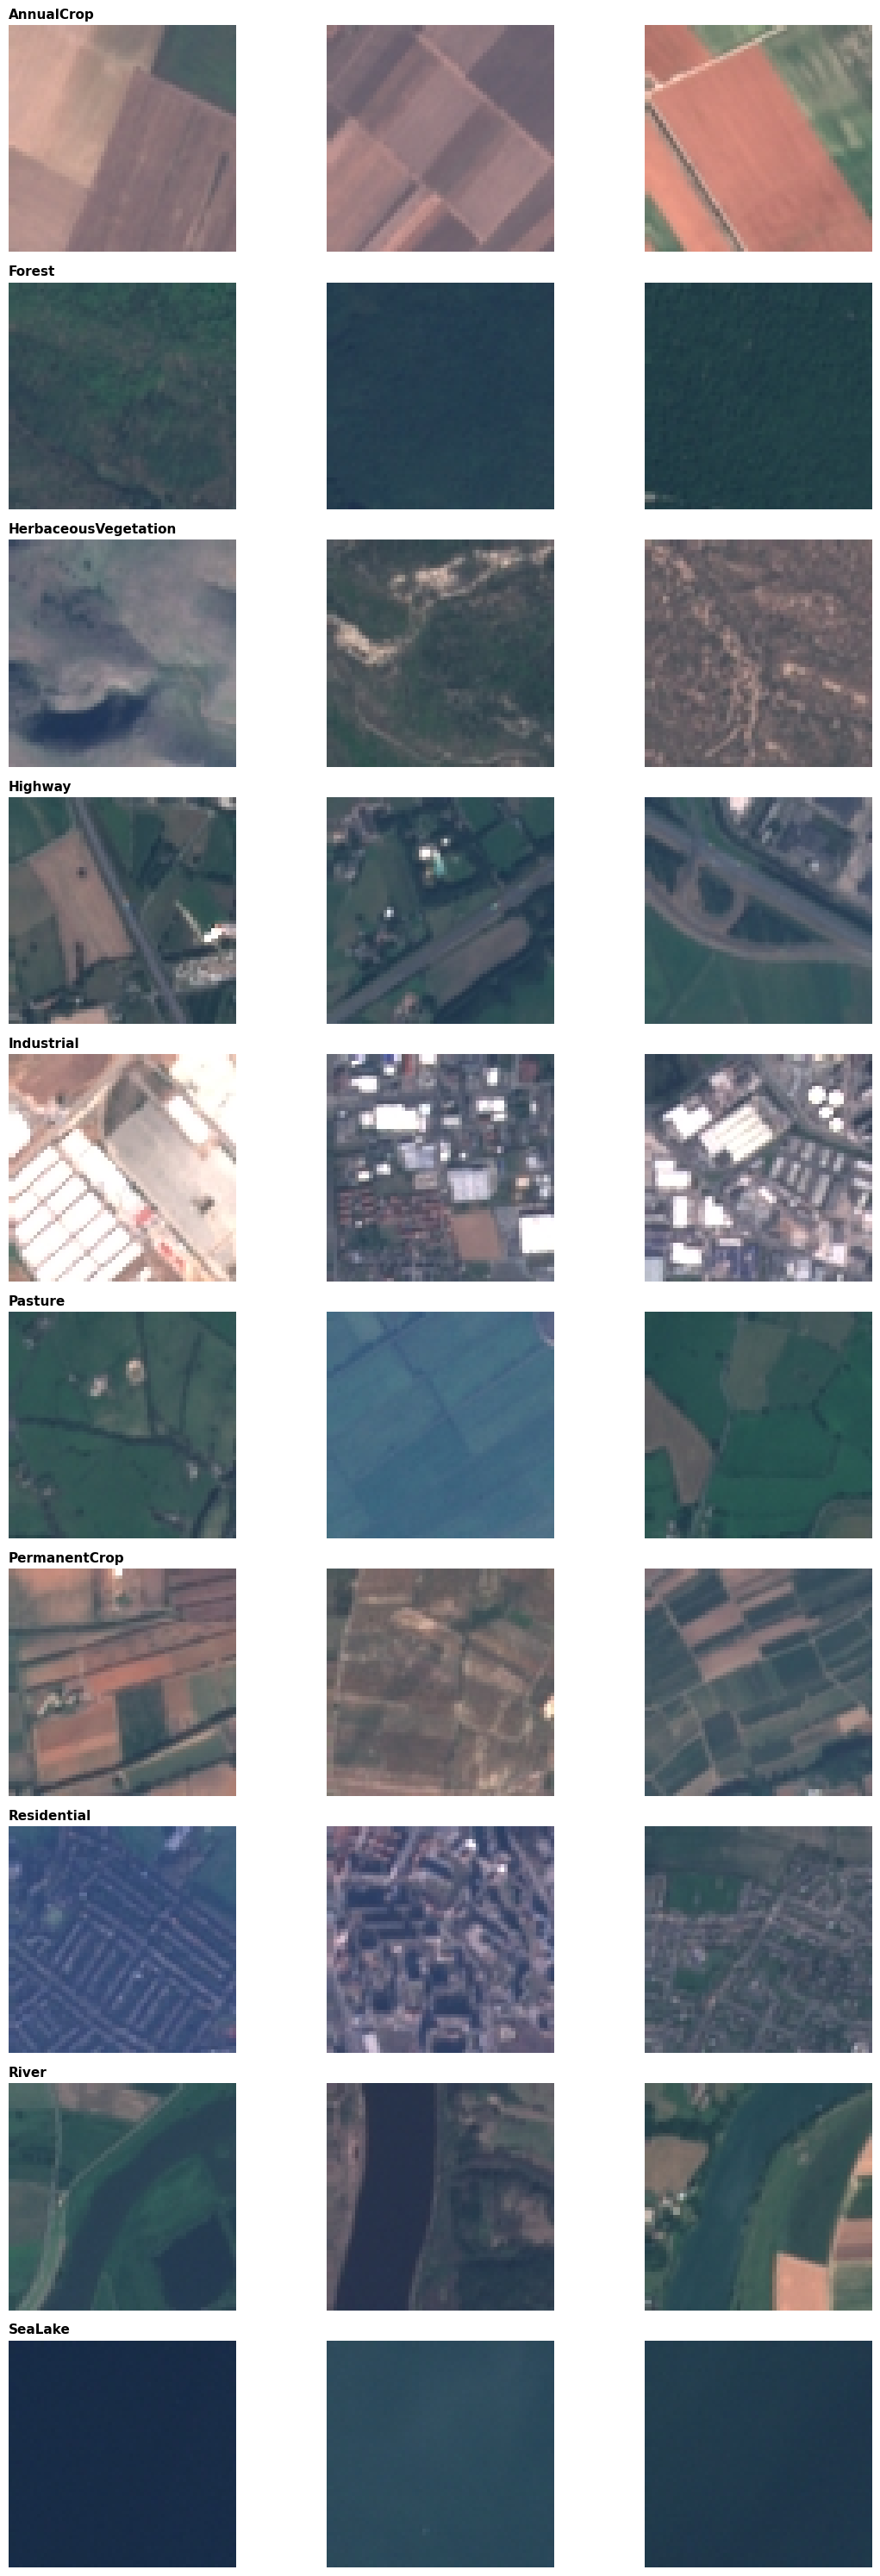

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Reproducible sample selection
SAMPLE_SEED = 42
sample_rng = random.Random(SAMPLE_SEED)

# Display three sample images from each class
class_names = sorted(EXPECTED_CLASSES)

fig, axes = plt.subplots(
    nrows=len(class_names),
    ncols=3,
    figsize=(12, 30)
)

for row, class_name in enumerate(class_names):

    class_path = os.path.join(DATASET_DIR, class_name)

    image_files = sorted([
        file_name
        for file_name in os.listdir(class_path)
        if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    # Select three reproducible sample images
    sample_images = sample_rng.sample(
        image_files,
        min(3, len(image_files))
    )

    for col, file_name in enumerate(sample_images):

        image_path = os.path.join(class_path, file_name)

        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(
                class_name,
                loc="left",
                fontsize=11,
                fontweight="bold"
            )

plt.tight_layout()
plt.show()

### 4.2 Class Distribution

We visualised the number of images in each land-use and land-cover class using a bar chart. This provides an overview of the class distribution and helps us understand whether the dataset is balanced.

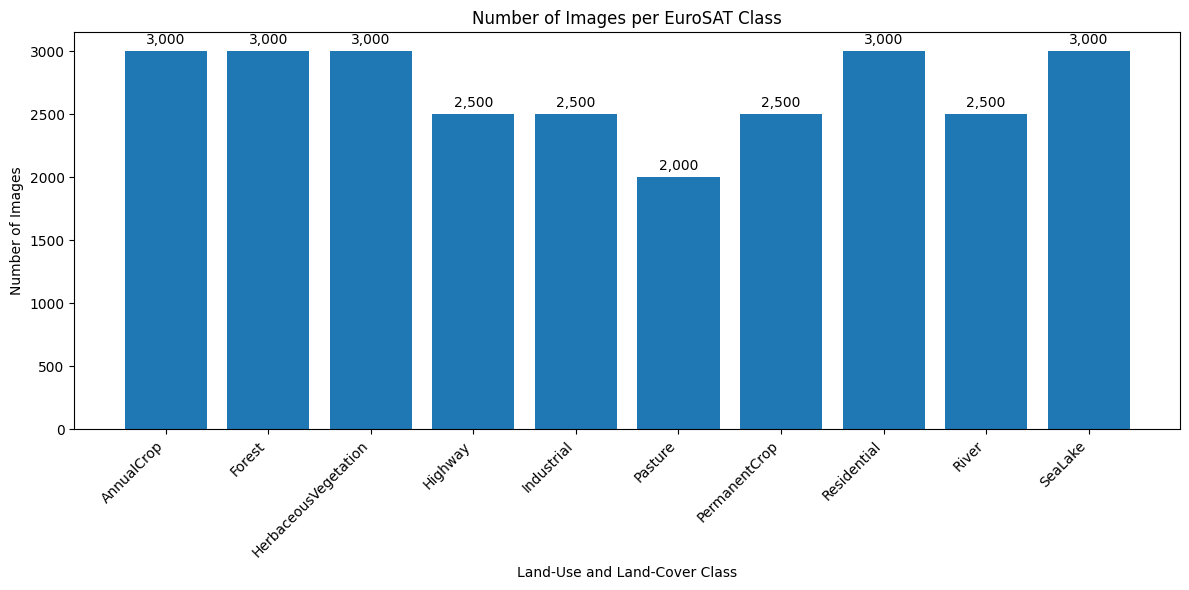

Image count per class:
AnnualCrop: 3,000
Forest: 3,000
HerbaceousVegetation: 3,000
Highway: 2,500
Industrial: 2,500
Pasture: 2,000
PermanentCrop: 2,500
Residential: 3,000
River: 2,500
SeaLake: 3,000

Total number of images: 27,000


In [6]:
from collections import Counter

# Count images in each class
class_counts = {}

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    image_files = [
        file_name
        for file_name in os.listdir(class_path)
        if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[class_name] = len(image_files)

# Plot class distribution
plt.figure(figsize=(12, 6))

bars = plt.bar(
    class_counts.keys(),
    class_counts.values()
)

# Display image counts above each bar
plt.bar_label(
    bars,
    labels=[f"{count:,}" for count in class_counts.values()],
    padding=3
)

plt.title("Number of Images per EuroSAT Class")
plt.xlabel("Land-Use and Land-Cover Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Print exact class counts
print("Image count per class:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count:,}")

print(f"\nTotal number of images: {sum(class_counts.values()):,}")

### 4.3 Checking Image Data Quality

We checked whether the image files could be opened successfully and whether they had the expected RGB format and image dimensions. This helped us identify any unreadable or incorrectly formatted images before training our models.

In [7]:
# Check image readability, dimensions, and colour mode

unreadable_images = []
unexpected_images = []

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in os.listdir(class_path):

        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(class_path, file_name)

        try:
            # Verify that the image file is readable
            with Image.open(image_path) as image:
                image.verify()

            # Reopen the image to check its properties
            with Image.open(image_path) as image:

                if image.size != (64, 64) or image.mode != "RGB":
                    unexpected_images.append(
                        (image_path, image.size, image.mode)
                    )

        except Exception:
            unreadable_images.append(image_path)


# Display quality-check results
print("IMAGE DATA QUALITY CHECK")
print("-" * 40)

print("Unreadable images:", len(unreadable_images))
print(
    "Images with unexpected dimensions or colour mode:",
    len(unexpected_images)
)

if unreadable_images:
    print("\nExamples of unreadable images:")
    for image_path in unreadable_images[:5]:
        print(image_path)

if unexpected_images:
    print("\nExamples of unexpected images:")
    for image_info in unexpected_images[:5]:
        print(image_info)

# Final status
if not unreadable_images and not unexpected_images:
    print("\nAll images passed the data quality checks!")
else:
    print("\nSome images did not pass the data quality checks.")

IMAGE DATA QUALITY CHECK
----------------------------------------
Unreadable images: 0
Images with unexpected dimensions or colour mode: 0

All images passed the data quality checks!


### 4.4 Inspecting Image Properties

We examined the dimensions, colour mode, and pixel values of a sample image to better understand how the satellite images are represented before preprocessing.

In [8]:
# Inspect properties of a reproducibly selected sample image

sample_class = "AnnualCrop"
sample_folder = os.path.join(DATASET_DIR, sample_class)

sample_files = sorted([
    file_name
    for file_name in os.listdir(sample_folder)
    if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Select a reproducible sample image
sample_rng = random.Random(42)
sample_file = sample_rng.choice(sample_files)

sample_path = os.path.join(sample_folder, sample_file)

with Image.open(sample_path) as image:
    sample_image = image.convert("RGB")
    image_array = np.array(sample_image)

print("Sample class:", sample_class)
print("Sample image:", sample_file)
print("Image dimensions:", sample_image.size)
print("Colour mode:", sample_image.mode)
print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Sample class: AnnualCrop
Sample image: AnnualCrop_656.jpg
Image dimensions: (64, 64)
Colour mode: RGB
Array shape: (64, 64, 3)
Data type: uint8
Minimum pixel value: 71
Maximum pixel value: 222


### 4.5 Checking for Duplicate Images

We checked the dataset for exact duplicate image files using their MD5 hashes. This helped us identify whether identical files were present under different filenames.

In [9]:
import hashlib
from collections import defaultdict

# Store image hashes and their corresponding class/file names
image_hashes = defaultdict(list)

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in os.listdir(class_path):

        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(class_path, file_name)

        # Calculate MD5 hash in chunks
        md5 = hashlib.md5()

        with open(image_path, "rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                md5.update(chunk)

        file_hash = md5.hexdigest()

        image_hashes[file_hash].append(
            (class_name, file_name)
        )


# Identify groups of exact duplicate files
duplicate_groups = [
    files
    for files in image_hashes.values()
    if len(files) > 1
]

# Count additional duplicate copies
duplicate_file_count = sum(
    len(files) - 1
    for files in duplicate_groups
)

# Display results
print("Total image files checked:", sum(class_counts.values()))
print("Unique image hashes:", len(image_hashes))
print("Duplicate groups found:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_file_count)

if duplicate_groups:
    print("\nExamples of duplicate groups:")

    for group in duplicate_groups[:10]:
        print(group)

else:
    print("No exact duplicate files found.")

Total image files checked: 27000
Unique image hashes: 27000
Duplicate groups found: 0
Extra duplicate files: 0
No exact duplicate files found.


### 4.6 Dataset-Wide Pixel and Missing-Value Checks

We checked the pixel-value range and missing pixel values across all readable images. We also verified that every image has a valid class label from its folder name.

In [10]:
# ============================================================
# 4.6 Dataset-Wide Pixel and Missing-Value Checks
# ============================================================

pixel_min = []
pixel_max = []

missing_pixels = 0
checked_images = 0
unexpected_images = []

# Check expected and actual class folders
actual_classes = {
    name
    for name in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, name))
}

expected_classes_set = set(EXPECTED_CLASSES)

invalid_labels = actual_classes - expected_classes_set
missing_classes = expected_classes_set - actual_classes


# Check all images in the expected class folders
for class_name in sorted(EXPECTED_CLASSES):

    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for file_name in os.listdir(class_path):

        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(class_path, file_name)

        with Image.open(image_path) as image:
            pixels = np.array(image.convert("RGB"))

        # Pixel-value range
        pixel_min.append(pixels.min())
        pixel_max.append(pixels.max())

        # Missing pixel values
        missing_pixels += np.isnan(pixels).sum()

        # Image properties
        if pixels.shape != (64, 64, 3):
            unexpected_images.append(
                (image_path, pixels.shape)
            )

        checked_images += 1


# Display results
print("DATASET-WIDE CHECKS")
print("-" * 40)

print("Images checked:", checked_images)
print("Dataset-wide minimum pixel value:", min(pixel_min))
print("Dataset-wide maximum pixel value:", max(pixel_max))
print("Missing pixel values:", missing_pixels)

print("Unexpected class folders:", invalid_labels)
print("Missing expected class folders:", missing_classes)
print("Images with unexpected shape:", len(unexpected_images))


# Display examples if any issues were detected
if unexpected_images:
    print("\nExamples of images with unexpected shapes:")

    for image_info in unexpected_images[:5]:
        print(image_info)


# Final verification
assert checked_images == EXPECTED_TOTAL_IMAGES, (
    f"Expected {EXPECTED_TOTAL_IMAGES} images, "
    f"but found {checked_images}."
)

assert len(invalid_labels) == 0, (
    f"Unexpected class folders found: {invalid_labels}"
)

assert len(missing_classes) == 0, (
    f"Missing expected class folders: {missing_classes}"
)

assert missing_pixels == 0, (
    f"Missing pixel values detected: {missing_pixels}"
)

assert len(unexpected_images) == 0, (
    f"Unexpected image shapes found: {len(unexpected_images)}"
)

assert min(pixel_min) >= 0
assert max(pixel_max) <= 255

print("\nAll dataset-wide checks passed!")

DATASET-WIDE CHECKS
----------------------------------------
Images checked: 27000
Dataset-wide minimum pixel value: 0
Dataset-wide maximum pixel value: 255
Missing pixel values: 0
Unexpected class folders: set()
Missing expected class folders: set()
Images with unexpected shape: 0

All dataset-wide checks passed!


# 5. Data Preparation

After exploring the dataset and checking its quality, we prepared the image paths and corresponding class labels for model training.

We divided the dataset into training, validation, and test sets using a stratified split to preserve the class distribution.

Following the reference paper, 80% of the images are reserved for training and validation, while 20% are held out for testing. The validation set is derived from the training portion and is used for model selection and tuning.

The test set is kept separate and is used for final evaluation after model development.

### 5.1 Collecting Image Paths and Labels

We collected the paths of all images along with their corresponding class labels. These labels will be used as the target values during model training.

In [11]:
image_paths = []
image_labels = []

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in sorted(os.listdir(class_path)):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_path, file_name))
            image_labels.append(class_name)

print("Total image paths:", len(image_paths))
print("Total labels:", len(image_labels))
print("First image path:", image_paths[0])
print("First image label:", image_labels[0])

Total image paths: 27000
Total labels: 27000
First image path: /content/EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg
First image label: AnnualCrop


### 5.2 Splitting the Dataset

We divided the 27,000 EuroSAT images into training, validation, and test sets using stratified sampling. This approach preserves the proportion of each land-use and land-cover class across all three sets.

- **Training set (72%):** 19,440 images used to train the models.
- **Validation set (8%):** 2,160 images used to monitor model performance and guide model selection.
- **Test set (20%):** 5,400 images reserved for final evaluation.

The training and validation sets together account for 80% of the dataset, following the train/test split used in the reference paper. The validation set is derived from the 80% training portion.

We use a fixed random seed of 42 to make the split reproducible. Both ResNet-50 and ResNet-18 will use the same split to ensure a fair comparison.

#### Split Integrity and Class Distribution Checks

After splitting the dataset, we verify the sizes of all three sets and check for overlapping image paths. We confirm that no images are shared between the training, validation, and test sets and that all 27,000 images are accounted for.

We also examine the class distribution in each split to confirm that stratified sampling preserves the expected class proportions.

In [16]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Fixed random seed for reproducibility
RANDOM_SEED = 42

# --------------------------------------------------
# Step 1: Split the dataset into 80% train/validation
#         and 20% test sets
# --------------------------------------------------

X_train_val, X_test, y_train_val, y_test = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,              # 20% reserved for testing
    random_state=RANDOM_SEED,
    stratify=image_labels        # Preserve class proportions
)

# --------------------------------------------------
# Step 2: Split the remaining 80% into training
#         and validation sets
# --------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.10,              # 10% of 80% = 8% of full dataset
    random_state=RANDOM_SEED,
    stratify=y_train_val         # Preserve class proportions
)

# --------------------------------------------------
# Step 3: Display and verify split sizes
# --------------------------------------------------

print("DATASET SPLIT SIZES")
print("-" * 35)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

# Verify the expected split sizes
assert len(X_train) == 19440
assert len(X_val) == 2160
assert len(X_test) == 5400

# --------------------------------------------------
# Step 4: Check for overlap between dataset splits
# --------------------------------------------------

train_paths = set(X_train)
val_paths = set(X_val)
test_paths = set(X_test)

# Combine all paths to verify that every image is accounted for
all_split_paths = train_paths | val_paths | test_paths

print("\nSPLIT INTEGRITY CHECKS")
print("-" * 35)

print("Train/validation overlap:", len(train_paths & val_paths))
print("Train/test overlap:", len(train_paths & test_paths))
print("Validation/test overlap:", len(val_paths & test_paths))
print("Unique image paths:", len(all_split_paths))

# Verify that there are no overlapping images
assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

# Verify that all 27,000 images are accounted for
assert len(all_split_paths) == 27000

# --------------------------------------------------
# Step 5: Display class distribution across splits
# --------------------------------------------------

# Combine the class labels and their corresponding split names
split_labels = pd.DataFrame({
    "class_name": (
        y_train
        + y_val
        + y_test
    ),
    "split": (
        ["train"] * len(y_train)
        + ["validation"] * len(y_val)
        + ["test"] * len(y_test)
    )
})

# Create a table showing the number of images per class in each split
class_distribution = pd.crosstab(
    split_labels["class_name"],
    split_labels["split"]
)

# Arrange the columns in the correct order
class_distribution = class_distribution[
    ["train", "validation", "test"]
]

print("\nCLASS DISTRIBUTION")
print("-" * 35)
print(class_distribution)

# --------------------------------------------------
# Step 6: Confirm that all checks passed
# --------------------------------------------------

print("\nAll dataset splitting and integrity checks passed!")


DATASET SPLIT SIZES
-----------------------------------
Training images: 19440
Validation images: 2160
Test images: 5400
Total images: 27000

SPLIT INTEGRITY CHECKS
-----------------------------------
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
Unique image paths: 27000

CLASS DISTRIBUTION
-----------------------------------
split                 train  validation  test
class_name                                   
AnnualCrop             2160         240   600
Forest                 2160         240   600
HerbaceousVegetation   2160         240   600
Highway                1800         200   500
Industrial             1800         200   500
Pasture                1440         160   400
PermanentCrop          1800         200   500
Residential            2160         240   600
River                  1800         200   500
SeaLake                2160         240   600

All dataset splitting and integrity checks passed!


### 5.3 Saving the Dataset Splits and Class Mapping

We saved the dataset split assignments in a CSV file containing each image's relative path, class name, numerical class index, and split assignment. We also saved the class-to-index mapping in a JSON file.

Saving these files allows us to reuse the same data splits and consistent class labels across both models, supporting reproducibility and a fair comparison.

In [17]:
# ==================================================
# 5.3 Saving the Dataset Splits and Class Mapping
# ==================================================

import os
import json
import pandas as pd

# --------------------------------------------------
# Step 1: Create a consistent class-to-index mapping
# --------------------------------------------------

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(sorted(EXPECTED_CLASSES))
}

# --------------------------------------------------
# Step 2: Collect image paths, labels, and split names
# --------------------------------------------------

records = []

split_data = [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]

for split_name, paths, labels in split_data:
    for path, label in zip(paths, labels):

        # Save relative paths for portability
        relative_path = os.path.relpath(path, DATASET_DIR)

        records.append({
            "relative_path": relative_path,
            "class_name": label,
            "class_idx": class_to_idx[label],
            "split": split_name
        })

# --------------------------------------------------
# Step 3: Create the Google Drive output directory
# --------------------------------------------------

SPLIT_DIR = (
    "/content/drive/MyDrive/EuroSAT_Final_Experiments/"
    "Shared/Dataset_Splits"
)

os.makedirs(SPLIT_DIR, exist_ok=True)

# --------------------------------------------------
# Step 4: Save the dataset split assignments
# --------------------------------------------------

splits_df = pd.DataFrame(records)

SPLIT_CSV_PATH = os.path.join(
    SPLIT_DIR,
    "eurosat_splits.csv"
)

splits_df.to_csv(SPLIT_CSV_PATH, index=False)

# --------------------------------------------------
# Step 5: Save the class-to-index mapping
# --------------------------------------------------

CLASS_MAPPING_PATH = os.path.join(
    SPLIT_DIR,
    "class_to_idx.json"
)

with open(CLASS_MAPPING_PATH, "w") as file:
    json.dump(class_to_idx, file, indent=2)

# --------------------------------------------------
# Step 6: Verify saved files
# --------------------------------------------------

print("DATASET SPLITS AND CLASS MAPPING SAVED")
print("-" * 45)

print("Split CSV:", SPLIT_CSV_PATH)
print("Class mapping:", CLASS_MAPPING_PATH)

print("\nFile existence checks:")
print("CSV exists:", os.path.exists(SPLIT_CSV_PATH))
print("JSON exists:", os.path.exists(CLASS_MAPPING_PATH))

print("\nNumber of records:", len(splits_df))

print("\nImages per split:")
print(splits_df["split"].value_counts())

print("\nClass-to-index mapping:")
print(class_to_idx)

print("\nFirst five records:")
print(splits_df.head())

# --------------------------------------------------
# Step 7: Verify expected split counts
# --------------------------------------------------

expected_split_counts = {
    "train": 19440,
    "validation": 2160,
    "test": 5400
}

actual_split_counts = splits_df["split"].value_counts().to_dict()

assert len(splits_df) == 27000
assert actual_split_counts == expected_split_counts
assert splits_df["relative_path"].is_unique
assert splits_df["class_idx"].notna().all()

# Verify both files exist and are non-empty
assert os.path.getsize(SPLIT_CSV_PATH) > 0
assert os.path.getsize(CLASS_MAPPING_PATH) > 0

# Verify the saved CSV can be loaded
saved_splits_df = pd.read_csv(SPLIT_CSV_PATH)

assert len(saved_splits_df) == 27000
assert list(saved_splits_df.columns) == [
    "relative_path",
    "class_name",
    "class_idx",
    "split"
]

# Verify the saved JSON can be loaded
with open(CLASS_MAPPING_PATH, "r") as file:
    saved_class_to_idx = json.load(file)

assert saved_class_to_idx == class_to_idx

print("\nAll dataset split and class mapping checks passed!")

DATASET SPLITS AND CLASS MAPPING SAVED
---------------------------------------------
Split CSV: /content/drive/MyDrive/EuroSAT_Final_Experiments/Shared/Dataset_Splits/eurosat_splits.csv
Class mapping: /content/drive/MyDrive/EuroSAT_Final_Experiments/Shared/Dataset_Splits/class_to_idx.json

File existence checks:
CSV exists: True
JSON exists: True

Number of records: 27000

Images per split:
split
train         19440
test           5400
validation     2160
Name: count, dtype: int64

Class-to-index mapping:
{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

First five records:
                    relative_path  class_name  class_idx  split
0  Industrial/Industrial_1389.jpg  Industrial          4  train
1          Forest/Forest_2296.jpg      Forest          1  train
2         Highway/Highway_274.jpg     Highway          3  train
3   Industrial/Industrial_622.jpg  Industrial

### 5.4 Preparing Images for Model Training

Before training the deep learning models, we prepared the data-loading pipeline in PyTorch. We reused the saved dataset split assignments and class-to-index mapping to maintain consistent image assignments and labels throughout the experiments.

In [18]:
# ==================================================
# 5.4 Preparing Images for Model Training
# ==================================================

import os
import json
import pandas as pd

# --------------------------------------------------
# Step 1: Define dataset and saved split locations
# --------------------------------------------------

DATASET_DIR = "/content/EuroSAT_RGB"

SPLIT_DIR = (
    "/content/drive/MyDrive/EuroSAT_Final_Experiments/"
    "Shared/Dataset_Splits"
)

SPLIT_CSV_PATH = os.path.join(
    SPLIT_DIR,
    "eurosat_splits.csv"
)

CLASS_MAPPING_PATH = os.path.join(
    SPLIT_DIR,
    "class_to_idx.json"
)

# --------------------------------------------------
# Step 2: Load the saved split assignments
# --------------------------------------------------

splits_df = pd.read_csv(SPLIT_CSV_PATH)

# Load the saved class-to-index mapping
with open(CLASS_MAPPING_PATH, "r") as file:
    class_to_idx = json.load(file)

# --------------------------------------------------
# Step 3: Display the saved split information
# --------------------------------------------------

print("Total saved records:", len(splits_df))

print("\nImages per split:")
print(splits_df["split"].value_counts())

print("\nNumber of classes:", len(class_to_idx))

print("\nClass mapping:")
print(class_to_idx)

# --------------------------------------------------
# Step 4: Verify the expected split sizes
# --------------------------------------------------

expected_split_counts = {
    "train": 19440,
    "validation": 2160,
    "test": 5400
}

actual_split_counts = splits_df["split"].value_counts().to_dict()

assert len(splits_df) == 27000
assert actual_split_counts == expected_split_counts
assert len(class_to_idx) == 10

# Verify expected columns
expected_columns = [
    "relative_path",
    "class_name",
    "class_idx",
    "split"
]

assert list(splits_df.columns) == expected_columns

# Verify class names and indices
assert set(splits_df["class_name"]) == set(class_to_idx.keys())

assert all(
    class_to_idx[class_name] == class_idx
    for class_name, class_idx in zip(
        splits_df["class_name"],
        splits_df["class_idx"]
    )
)

# --------------------------------------------------
# Step 5: Verify that all saved image paths exist
# --------------------------------------------------

image_paths_exist = splits_df["relative_path"].apply(
    lambda path: os.path.isfile(
        os.path.join(DATASET_DIR, path)
    )
)

assert image_paths_exist.all()

# --------------------------------------------------
# Step 6: Confirm successful loading and verification
# --------------------------------------------------

print("\nAll saved image paths exist:", image_paths_exist.all())

print("\nSaved split information loaded and verified successfully!")

Total saved records: 27000

Images per split:
split
train         19440
test           5400
validation     2160
Name: count, dtype: int64

Number of classes: 10

Class mapping:
{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

All saved image paths exist: True

Saved split information loaded and verified successfully!


#### 5.4.1 Image Preprocessing and Data Loading

We used PyTorch to load the EuroSAT images and their corresponding numerical labels. Each image was converted into a tensor and normalized using the ImageNet channel means and standard deviations, which are appropriate for our pretrained ResNet models.

We retained the original image resolution of 64 × 64 pixels. The images were then organized into batches using PyTorch DataLoaders. The training loader shuffles the training images, while the validation and test loaders preserve their order.

In [19]:
# ==================================================
# 5.4.1 Image Preprocessing and Data Loading
# ==================================================

import os
import random
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# --------------------------------------------------
# Step 1: Define image preprocessing
# --------------------------------------------------

# ImageNet normalization values for pretrained ResNet models
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Convert images to tensors and normalize them
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# --------------------------------------------------
# Step 2: Define the custom EuroSAT dataset
# --------------------------------------------------

class EuroSATDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = os.path.join(
            self.root_dir,
            row["relative_path"]
        )

        # Load image and ensure three RGB channels
        with Image.open(image_path) as image:
            image = image.convert("RGB")

        # Apply preprocessing
        if self.transform is not None:
            image = self.transform(image)

        # Retrieve numerical class label
        label = int(row["class_idx"])

        return image, label

# --------------------------------------------------
# Step 3: Separate the saved dataset splits
# --------------------------------------------------

train_df = splits_df[splits_df["split"] == "train"].copy()
val_df = splits_df[splits_df["split"] == "validation"].copy()
test_df = splits_df[splits_df["split"] == "test"].copy()

# --------------------------------------------------
# Step 4: Create dataset objects
# --------------------------------------------------

train_dataset = EuroSATDataset(
    train_df,
    DATASET_DIR,
    image_transform
)

val_dataset = EuroSATDataset(
    val_df,
    DATASET_DIR,
    image_transform
)

test_dataset = EuroSATDataset(
    test_df,
    DATASET_DIR,
    image_transform
)

# --------------------------------------------------
# Step 5: Set reproducible DataLoader configuration
# --------------------------------------------------

BATCH_SIZE = 64
DATALOADER_SEED = 42

# Generator controls reproducible training shuffle order
train_generator = torch.Generator()
train_generator.manual_seed(DATALOADER_SEED)

# Worker initialization for reproducibility
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# --------------------------------------------------
# Step 6: Create DataLoaders
# --------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    worker_init_fn=seed_worker,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Step 7: Verify dataset sizes and inspect one batch
# --------------------------------------------------

print("DATASET SIZES")
print("-" * 40)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

images, labels = next(iter(train_loader))

print("\nFIRST TRAINING BATCH")
print("-" * 40)
print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Image tensor data type:", images.dtype)
print("Label tensor data type:", labels.dtype)
print("Minimum normalized value:", images.min().item())
print("Maximum normalized value:", images.max().item())

# --------------------------------------------------
# Step 8: Verify batch and label properties
# --------------------------------------------------

assert images.shape == (BATCH_SIZE, 3, 64, 64)
assert labels.shape == (BATCH_SIZE,)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert labels.min().item() >= 0
assert labels.max().item() < len(class_to_idx)

assert len(train_dataset) == 19440
assert len(val_dataset) == 2160
assert len(test_dataset) == 5400

print("\nAll dataset and DataLoader checks passed!")

DATASET SIZES
----------------------------------------
Training: 19440
Validation: 2160
Test: 5400

FIRST TRAINING BATCH
----------------------------------------
Image tensor shape: torch.Size([64, 3, 64, 64])
Label tensor shape: torch.Size([64])
Image tensor data type: torch.float32
Label tensor data type: torch.int64
Minimum normalized value: -1.7754088640213013
Maximum normalized value: 2.640000104904175

All dataset and DataLoader checks passed!


# 6. ResNet-50 Baseline

## 6.1 Model Configuration and Training Strategy

We use an ImageNet-pretrained ResNet-50 as the baseline classifier for the ten EuroSAT land-use and land-cover classes. The final fully connected layer is replaced with a new layer containing ten output units, one for each class.

Training follows the two-stage transfer-learning strategy described in the reference paper. First, the pretrained feature extractor is frozen, and the newly initialized classification layer is trained using a learning rate of 0.01. Second, the entire network is fine-tuned using a lower learning rate in the range of 0.001–0.0001.

The AdamW optimizer is used for both stages as an experimental choice for this reimplementation. Other training settings, including the number of epochs and batch size, are documented separately where they are not explicitly specified in the original paper.

Model performance is monitored using the validation set, and the checkpoint with the highest validation accuracy is retained. Multiple random seeds are used to assess variability across training runs.

The test set remains separate from model training and selection and is reserved for final evaluation.

In [20]:
# ==================================================
# 6. RESNET-50 BASELINE
# 6.1 Model Configuration and Training Strategy
# ==================================================

import os
import random
import time
import copy
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import models
from pathlib import Path

# --------------------------------------------------
# 1. Reproducibility and training configuration
# --------------------------------------------------

# Use three random seeds to assess variability across runs
SEEDS = [42, 43, 44]

# Number of EuroSAT classes
NUM_CLASSES = 10

# Number of images processed in each training batch
BATCH_SIZE = 64

# Stage 1: Train only the new classification layer
HEAD_EPOCHS = 3
HEAD_LR = 0.01

# Stage 2: Fine-tune the entire ResNet-50 network
FINETUNE_EPOCHS = 7
FINETUNE_LR = 0.0001

# AdamW regularization
WEIGHT_DECAY = 1e-4

# Total number of epochs per run
TOTAL_EPOCHS = HEAD_EPOCHS + FINETUNE_EPOCHS

# --------------------------------------------------
# 2. Select the computing device
# --------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# --------------------------------------------------
# 3. Load the class mapping from Google Drive
# --------------------------------------------------

SPLIT_DIR = (
    "/content/drive/MyDrive/EuroSAT_Final_Experiments/"
    "Shared/Dataset_Splits"
)

CLASS_MAPPING_PATH = os.path.join(
    SPLIT_DIR,
    "class_to_idx.json"
)

if not os.path.exists(CLASS_MAPPING_PATH):
    raise FileNotFoundError(
        "class_to_idx.json was not found in Google Drive. "
        "Please run Sections 5.3 and 5.4 first."
    )

with open(CLASS_MAPPING_PATH, "r") as file:
    class_to_idx = json.load(file)

# Arrange class names according to their numerical indices
class_names = [
    name
    for name, index in sorted(
        class_to_idx.items(),
        key=lambda item: item[1]
    )
]

# Verify the class mapping
assert len(class_to_idx) == NUM_CLASSES
assert sorted(class_to_idx.values()) == list(range(NUM_CLASSES))

# --------------------------------------------------
# 4. Define the baseline experiment directories
# --------------------------------------------------

BASELINE_DIR = Path(
    "/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline"
)

CHECKPOINT_DIR = BASELINE_DIR / "Checkpoints"
RESULTS_DIR = BASELINE_DIR / "Results"
LOGS_DIR = BASELINE_DIR / "Logs"

# Ensure the directories exist
for directory in [
    CHECKPOINT_DIR,
    RESULTS_DIR,
    LOGS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 5. Display the training configuration
# --------------------------------------------------

print("=" * 55)
print("RESNET-50 BASELINE CONFIGURATION")
print("=" * 55)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable; training on CPU may be slow.")

print("\nNumber of classes:", len(class_names))
print("Class mapping:", class_to_idx)
print("Random seeds:", SEEDS)

print("\nStage 1: Classification head training")
print("Epochs:", HEAD_EPOCHS)
print("Learning rate:", HEAD_LR)

print("\nStage 2: Full-network fine-tuning")
print("Epochs:", FINETUNE_EPOCHS)
print("Learning rate:", FINETUNE_LR)

print("\nOptimizer: AdamW")
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Total epochs per run:", TOTAL_EPOCHS)

print("\nCheckpoint directory:", CHECKPOINT_DIR)
print("Results directory:", RESULTS_DIR)
print("Logs directory:", LOGS_DIR)

# --------------------------------------------------
# 6. Validate the prepared dataset splits
# --------------------------------------------------

# Verify split sizes using the datasets from Section 5.4.1
assert len(train_dataset) == 19440, "Incorrect training split size."
assert len(val_dataset) == 2160, "Incorrect validation split size."
assert len(test_dataset) == 5400, "Incorrect test split size."

# Confirm total number of images
assert (
    len(train_dataset)
    + len(val_dataset)
    + len(test_dataset)
) == 27000, "Incorrect total number of images."

# Verify DataLoader batch size
assert train_loader.batch_size == BATCH_SIZE
assert val_loader.batch_size == BATCH_SIZE
assert test_loader.batch_size == BATCH_SIZE

print("\nAll configuration and split-size checks passed!")

RESNET-50 BASELINE CONFIGURATION
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4

Number of classes: 10
Class mapping: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}
Random seeds: [42, 43, 44]

Stage 1: Classification head training
Epochs: 3
Learning rate: 0.01

Stage 2: Full-network fine-tuning
Epochs: 7
Learning rate: 0.0001

Optimizer: AdamW
Weight decay: 0.0001
Batch size: 64
Total epochs per run: 10

Checkpoint directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Checkpoints
Results directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results
Logs directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Logs

All configuration and split-size checks passed!



## 6.2 ResNet-50 Model and Training

In this section, we implement the ResNet-50 baseline for EuroSAT land-use and land-cover classification. We use an ImageNet-pretrained ResNet-50 model and replace its final fully connected layer to predict the ten EuroSAT classes.

Training is performed in two stages. First, we train the newly initialized classification head while keeping the pretrained feature-extraction layers frozen. Second, we fine-tune the entire network using a lower learning rate.

We use the AdamW optimizer with weight decay and evaluate model performance on the validation set after each epoch. The best model is selected based on validation accuracy. This process is repeated using three random seeds (42, 43, and 44) to assess the consistency of the results.

The test set is reserved for final evaluation after model selection. The experimental settings are documented as our implementation choices; they are not assumed to reproduce every detail of the original paper.


In [21]:
# ============================================================
# 6.2 ResNet-50 Model and Training
# ============================================================

import copy
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

def set_seed(seed):
    """Set random seeds for reproducible experiments."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# 2. Build ResNet-50
# ------------------------------------------------------------

def build_resnet50(num_classes):
    """Load ImageNet-pretrained ResNet-50 and replace its classifier."""

    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )

    # Replace the final fully connected layer
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    return model.to(DEVICE)


# ------------------------------------------------------------
# 3. Run one training or validation epoch
# ------------------------------------------------------------

def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    train_head_only=False
):
    """
    Run one epoch.

    If optimizer is provided, perform training.
    Otherwise, perform validation.
    """

    is_training = optimizer is not None

    if train_head_only:
        # Keep pretrained feature extractor frozen in evaluation mode
        model.eval()
        model.fc.train()
    elif is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.set_grad_enabled(is_training):

        for images, labels in loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if is_training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            # Calculate batch statistics
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()

            total_samples += batch_size

    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 4. Train one ResNet-50 model for a given seed
# ------------------------------------------------------------

def train_resnet50(seed):

    print("\n" + "=" * 70)
    print(f"Training ResNet-50 | Seed: {seed}")
    print("=" * 70)

    # Set seed for this experiment
    set_seed(seed)

    # Reset the training DataLoader shuffle generator
    if getattr(train_loader, "generator", None) is not None:
        train_loader.generator.manual_seed(seed)

    # Build model
    model = build_resnet50(NUM_CLASSES)

    # Loss function
    criterion = nn.CrossEntropyLoss()

    # Track the best validation model
    best_val_accuracy = -1.0
    best_val_loss = None
    best_epoch = None
    best_state = None

    history = []

    start_time = time.time()

    # ========================================================
    # Stage 1: Train classification head
    # ========================================================

    print("\nStage 1: Training classification head")
    print("-" * 70)

    # Freeze all model parameters
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze only the final fully connected layer
    for param in model.fc.parameters():
        param.requires_grad = True

    # Optimizer for classification head
    optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=HEAD_LR,
        weight_decay=WEIGHT_DECAY
    )

    for epoch in range(HEAD_EPOCHS):

        train_loss, train_accuracy = run_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            train_head_only=True
        )

        val_loss, val_accuracy = run_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            optimizer=None
        )

        epoch_number = epoch + 1

        history.append({
            "seed": seed,
            "stage": "head",
            "epoch": epoch_number,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        print(
            f"Head Epoch [{epoch_number}/{HEAD_EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        # Select best model using validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_val_loss = val_loss
            best_epoch = epoch_number

            best_state = copy.deepcopy(model.state_dict())


    # ========================================================
    # Stage 2: Fine-tune entire network
    # ========================================================

    print("\nStage 2: Fine-tuning entire network")
    print("-" * 70)

    # Unfreeze all model parameters
    for param in model.parameters():
        param.requires_grad = True

    # Optimizer for full network fine-tuning
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=FINETUNE_LR,
        weight_decay=WEIGHT_DECAY
    )

    for epoch in range(FINETUNE_EPOCHS):

        train_loss, train_accuracy = run_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            train_head_only=False
        )

        val_loss, val_accuracy = run_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            optimizer=None
        )

        epoch_number = HEAD_EPOCHS + epoch + 1

        history.append({
            "seed": seed,
            "stage": "fine_tune",
            "epoch": epoch_number,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        print(
            f"Fine-tune Epoch [{epoch + 1}/{FINETUNE_EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        # Select best model using validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_val_loss = val_loss
            best_epoch = epoch_number

            best_state = copy.deepcopy(model.state_dict())


    # --------------------------------------------------------
    # 5. Restore best validation model
    # --------------------------------------------------------

    assert best_state is not None, (
        "No best model state was saved."
    )

    model.load_state_dict(best_state)


    # --------------------------------------------------------
    # 6. Save best checkpoint to Google Drive
    # --------------------------------------------------------

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"resnet50_seed_{seed}.pth"
    )

    checkpoint = {
        "seed": seed,
        "model_name": "ResNet-50",
        "state_dict": model.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "class_to_idx": class_to_idx,
        "class_names": list(class_to_idx.keys()),
        "head_epochs": HEAD_EPOCHS,
        "finetune_epochs": FINETUNE_EPOCHS,
        "head_lr": HEAD_LR,
        "finetune_lr": FINETUNE_LR,
        "batch_size": BATCH_SIZE,
        "weight_decay": WEIGHT_DECAY
    }

    torch.save(checkpoint, checkpoint_path)


    # --------------------------------------------------------
    # 7. Save per-seed training history
    # --------------------------------------------------------

    history_df = pd.DataFrame(history)

    history_path = (
        LOGS_DIR /
        f"resnet50_seed_{seed}_training_history.csv"
    )

    history_df.to_csv(history_path, index=False)


    # --------------------------------------------------------
    # 8. Record training time
    # --------------------------------------------------------

    training_minutes = (time.time() - start_time) / 60

    print("\nBest model saved:")
    print(f"  Checkpoint: {checkpoint_path}")
    print(f"  Best Val Accuracy: {best_val_accuracy:.4f}")
    print(f"  Best Epoch: {best_epoch}")
    print(f"  Training Time: {training_minutes:.2f} minutes")

    return {
        "seed": seed,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "training_minutes": training_minutes,
        "checkpoint": str(checkpoint_path),
        "history": history
    }


# ------------------------------------------------------------
# 9. Run experiments for all three seeds
# ------------------------------------------------------------

all_results = []

for seed in SEEDS:

    result = train_resnet50(seed)

    all_results.append(result)


# ------------------------------------------------------------
# 10. Save combined training history
# ------------------------------------------------------------

all_history = []

for result in all_results:
    all_history.extend(result["history"])

history_df = pd.DataFrame(all_history)

history_path = (
    LOGS_DIR /
    "resnet50_training_history.csv"
)

history_df.to_csv(history_path, index=False)


# ------------------------------------------------------------
# 11. Save validation results
# ------------------------------------------------------------

validation_results_df = pd.DataFrame([
    {
        "seed": result["seed"],
        "best_val_accuracy": result["best_val_accuracy"],
        "best_val_loss": result["best_val_loss"],
        "best_epoch": result["best_epoch"],
        "training_minutes": result["training_minutes"],
        "checkpoint": result["checkpoint"]
    }
    for result in all_results
])

validation_results_path = (
    RESULTS_DIR /
    "resnet50_validation_results.csv"
)

validation_results_df.to_csv(
    validation_results_path,
    index=False
)


# ------------------------------------------------------------
# 12. Calculate mean and standard deviation
# ------------------------------------------------------------

mean_val_accuracy = validation_results_df[
    "best_val_accuracy"
].mean()

std_val_accuracy = validation_results_df[
    "best_val_accuracy"
].std(ddof=1)

summary_df = pd.DataFrame([{
    "model": "ResNet-50",
    "num_seeds": len(SEEDS),
    "mean_best_val_accuracy": mean_val_accuracy,
    "std_best_val_accuracy": std_val_accuracy
}])

summary_path = (
    RESULTS_DIR /
    "resnet50_validation_summary.csv"
)

summary_df.to_csv(summary_path, index=False)


# ------------------------------------------------------------
# 13. Display final results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESNET-50 BASELINE VALIDATION RESULTS")
print("=" * 70)

display(validation_results_df)

print(
    f"\nMean Validation Accuracy: "
    f"{mean_val_accuracy:.4f} "
    f"± {std_val_accuracy:.4f}"
)

print("\nSaved files:")
print(f"  Training history: {history_path}")
print(f"  Validation results: {validation_results_path}")
print(f"  Validation summary: {summary_path}")

print("\nAll three ResNet-50 seed runs completed successfully!")


Training ResNet-50 | Seed: 42
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 87.9MB/s]



Stage 1: Training classification head
----------------------------------------------------------------------
Head Epoch [1/3] | Train Loss: 0.5507 | Train Acc: 0.8771 | Val Loss: 0.5085 | Val Acc: 0.9046
Head Epoch [2/3] | Train Loss: 0.3019 | Train Acc: 0.9325 | Val Loss: 0.5918 | Val Acc: 0.9069
Head Epoch [3/3] | Train Loss: 0.1910 | Train Acc: 0.9538 | Val Loss: 0.6291 | Val Acc: 0.9060

Stage 2: Fine-tuning entire network
----------------------------------------------------------------------
Fine-tune Epoch [1/7] | Train Loss: 0.4190 | Train Acc: 0.8793 | Val Loss: 0.1616 | Val Acc: 0.9509
Fine-tune Epoch [2/7] | Train Loss: 0.0784 | Train Acc: 0.9764 | Val Loss: 0.1416 | Val Acc: 0.9551
Fine-tune Epoch [3/7] | Train Loss: 0.0307 | Train Acc: 0.9904 | Val Loss: 0.1276 | Val Acc: 0.9625
Fine-tune Epoch [4/7] | Train Loss: 0.0207 | Train Acc: 0.9933 | Val Loss: 0.1359 | Val Acc: 0.9653
Fine-tune Epoch [5/7] | Train Loss: 0.0160 | Train Acc: 0.9951 | Val Loss: 0.1293 | Val Acc: 0.97

,seed,best_val_accuracy,best_val_loss,best_epoch,training_minutes,checkpoint
0,42,0.971296,0.116938,9,4.658466,/content/drive/MyDrive/EuroSAT_Final_Experimen...
1,43,0.968981,0.131013,10,4.602584,/content/drive/MyDrive/EuroSAT_Final_Experimen...
2,44,0.968056,0.155633,10,4.579022,/content/drive/MyDrive/EuroSAT_Final_Experimen...



Mean Validation Accuracy: 0.9694 ± 0.0017

Saved files:
  Training history: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Logs/resnet50_training_history.csv
  Validation results: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_validation_results.csv
  Validation summary: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_validation_summary.csv

All three ResNet-50 seed runs completed successfully!


### 6.3 Training Curves

Training and validation loss and accuracy are visualized for each of the three random seeds (42, 43, and 44). These curves help assess model convergence, generalization, and training stability across the two training stages.

The first stage trains only the classification head, while the second stage fine-tunes the full ResNet-50 network. Validation performance is used to select the best checkpoint for each seed. The test set is not used during training or checkpoint selection.

Experiment: ResNet-50
Seeds: [np.int64(42), np.int64(43), np.int64(44)]
Number of training records: 30


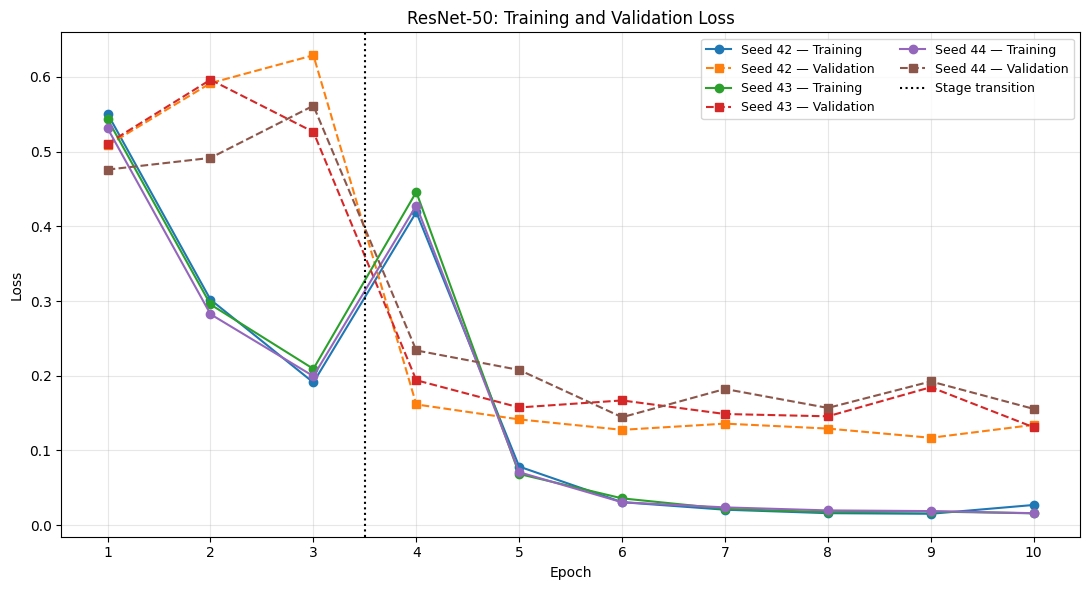

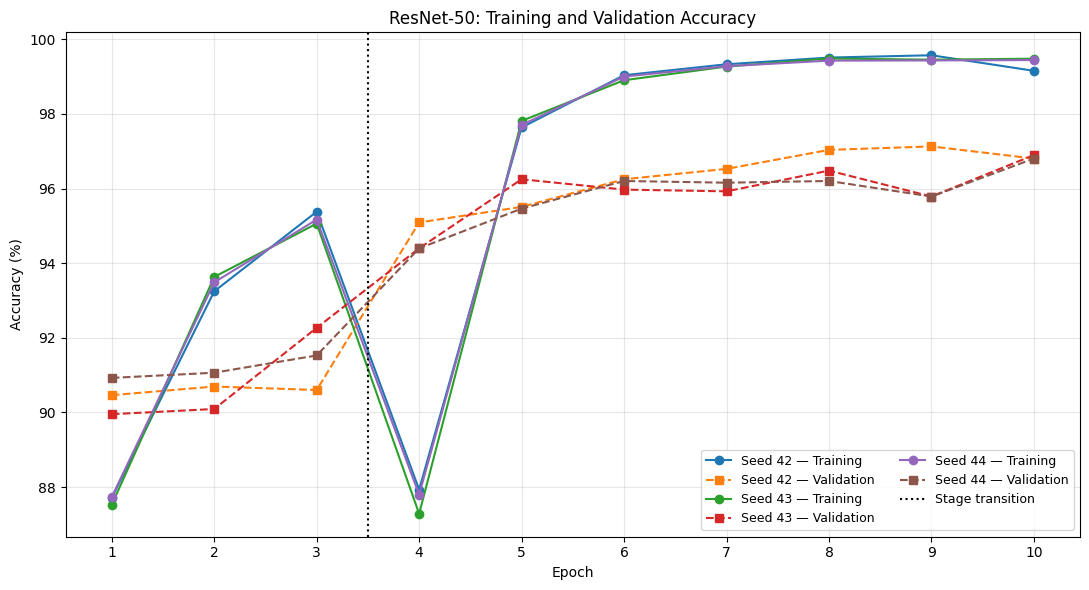


Training-curve visualizations completed.
Seeds plotted: [np.int64(42), np.int64(43), np.int64(44)]
Stage 1: Classification head training
Stage 2: Full-network fine-tuning

Training history: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Logs/resnet50_training_history.csv
Loss plot saved: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_training_validation_loss.png
Accuracy plot saved: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_training_validation_accuracy.png


In [22]:
# ============================================================
# 6.3 Training Curves
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


# ------------------------------------------------------------
# 1. Load the training history from Google Drive
# ------------------------------------------------------------

history_path = (
    LOGS_DIR /
    "resnet50_training_history.csv"
)

assert history_path.exists(), (
    f"Training history not found: {history_path}"
)

history_df = pd.read_csv(history_path)


# ------------------------------------------------------------
# 2. Display experiment information
# ------------------------------------------------------------

print("Experiment: ResNet-50")
print("Seeds:", sorted(history_df["seed"].unique()))
print("Number of training records:", len(history_df))


# ------------------------------------------------------------
# 3. Check the required columns
# ------------------------------------------------------------

required_columns = {
    "seed",
    "epoch",
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy"
}

missing_columns = required_columns - set(history_df.columns)

assert not missing_columns, (
    f"Missing columns in training history: {missing_columns}"
)

# Confirm that all expected seeds are present
assert sorted(history_df["seed"].unique()) == SEEDS, (
    "The training history does not contain all expected seeds."
)

# Each seed should have 10 epochs
for seed in SEEDS:

    seed_history = history_df[
        history_df["seed"] == seed
    ]

    assert len(seed_history) == (
        HEAD_EPOCHS + FINETUNE_EPOCHS
    ), f"Unexpected number of epochs for seed {seed}"


# ------------------------------------------------------------
# 4. Prepare data for plotting
# ------------------------------------------------------------

plot_df = history_df.copy()

plot_df = plot_df.sort_values(
    ["seed", "epoch"]
)

# Convert accuracy to percentage
plot_df["train_accuracy_pct"] = (
    plot_df["train_accuracy"] * 100
)

plot_df["val_accuracy_pct"] = (
    plot_df["val_accuracy"] * 100
)

seeds = sorted(
    plot_df["seed"].unique()
)


# ============================================================
# 5. Plot training and validation loss
# ============================================================

plt.figure(figsize=(11, 6))

for seed in seeds:

    seed_df = plot_df[
        plot_df["seed"] == seed
    ]

    # Training loss
    plt.plot(
        seed_df["epoch"],
        seed_df["train_loss"],
        marker="o",
        label=f"Seed {seed} — Training"
    )

    # Validation loss
    plt.plot(
        seed_df["epoch"],
        seed_df["val_loss"],
        marker="s",
        linestyle="--",
        label=f"Seed {seed} — Validation"
    )


# Mark the transition between training stages
plt.axvline(
    x=HEAD_EPOCHS + 0.5,
    linestyle=":",
    color="black",
    label="Stage transition"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet-50: Training and Validation Loss"
)

plt.xticks(
    range(
        1,
        HEAD_EPOCHS + FINETUNE_EPOCHS + 1
    )
)

plt.legend(
    ncol=2,
    fontsize=9
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


# Save loss plot to Google Drive
loss_plot_path = (
    RESULTS_DIR /
    "resnet50_training_validation_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. Plot training and validation accuracy
# ============================================================

plt.figure(figsize=(11, 6))

for seed in seeds:

    seed_df = plot_df[
        plot_df["seed"] == seed
    ]

    # Training accuracy
    plt.plot(
        seed_df["epoch"],
        seed_df["train_accuracy_pct"],
        marker="o",
        label=f"Seed {seed} — Training"
    )

    # Validation accuracy
    plt.plot(
        seed_df["epoch"],
        seed_df["val_accuracy_pct"],
        marker="s",
        linestyle="--",
        label=f"Seed {seed} — Validation"
    )


# Mark the transition between training stages
plt.axvline(
    x=HEAD_EPOCHS + 0.5,
    linestyle=":",
    color="black",
    label="Stage transition"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "ResNet-50: Training and Validation Accuracy"
)

plt.xticks(
    range(
        1,
        HEAD_EPOCHS + FINETUNE_EPOCHS + 1
    )
)

plt.legend(
    ncol=2,
    fontsize=9
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


# Save accuracy plot to Google Drive
accuracy_plot_path = (
    RESULTS_DIR /
    "resnet50_training_validation_accuracy.png"
)

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Confirm completion
# ------------------------------------------------------------

print("\nTraining-curve visualizations completed.")

print("Seeds plotted:", seeds)

print("Stage 1: Classification head training")
print("Stage 2: Full-network fine-tuning")

print(f"\nTraining history: {history_path}")
print(f"Loss plot saved: {loss_plot_path}")
print(f"Accuracy plot saved: {accuracy_plot_path}")

### 6.4 Test Set Evaluation

The best ResNet-50 checkpoint for each random seed was selected using validation accuracy. The selected checkpoints are evaluated on the held-out test set to assess their generalization performance.

The test set is not used for training, hyperparameter selection, or checkpoint selection. Accuracy, precision, recall, and F1-score are reported for each seed, along with the mean and standard deviation across the three runs.

In [23]:
# ============================================================
# 6.4 Test Set Evaluation
# ============================================================

import torch
import torch.nn as nn
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from torchvision import models
from pathlib import Path


# ------------------------------------------------------------
# 1. Verify test set and checkpoint directories
# ------------------------------------------------------------

assert len(test_dataset) == 5400, (
    "Unexpected test set size."
)

assert CHECKPOINT_DIR.exists(), (
    f"Checkpoint directory not found: {CHECKPOINT_DIR}"
)

assert RESULTS_DIR.exists(), (
    f"Results directory not found: {RESULTS_DIR}"
)

print("Test set size:", len(test_dataset))
print("Number of classes:", NUM_CLASSES)
print("Seeds:", SEEDS)

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\nResults directory:")
print(RESULTS_DIR)


# ------------------------------------------------------------
# 2. Evaluate one saved model on the test set
# ------------------------------------------------------------

def evaluate_resnet50(checkpoint_path, expected_seed):

    # Verify checkpoint exists
    assert checkpoint_path.exists(), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    # Load saved checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Verify seed
    assert checkpoint["seed"] == expected_seed, (
        f"Checkpoint seed mismatch: "
        f"expected {expected_seed}, "
        f"got {checkpoint['seed']}"
    )

    # Rebuild ResNet-50 architecture
    model = models.resnet50(
        weights=None
    )

    # Replace final classification layer
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    # Load trained model parameters
    model.load_state_dict(
        checkpoint["state_dict"]
    )

    # Move model to GPU or CPU
    model = model.to(DEVICE)

    # Evaluation mode
    model.eval()

    all_predictions = []
    all_labels = []

    # Disable gradient computation
    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            # Forward pass
            outputs = model(images)

            # Predicted class
            predictions = outputs.argmax(
                dim=1
            )

            # Store predictions and true labels
            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    # Convert to NumPy arrays
    all_predictions = np.array(
        all_predictions
    )

    all_labels = np.array(
        all_labels
    )

    # --------------------------------------------------------
    # Calculate evaluation metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    # Classification report
    report = classification_report(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=list(class_to_idx.keys()),
        output_dict=True,
        zero_division=0
    )

    # Confusion matrix
    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES))
    )

    return {
        "seed": expected_seed,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "predictions": all_predictions,
        "labels": all_labels,
        "classification_report": report,
        "confusion_matrix": cm
    }


# ------------------------------------------------------------
# 3. Evaluate all three seeds
# ------------------------------------------------------------

test_results = []
test_predictions = {}

for seed in SEEDS:

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"resnet50_seed_{seed}.pth"
    )

    print("\n" + "=" * 60)
    print(f"Evaluating ResNet-50 | Seed {seed}")
    print("=" * 60)

    result = evaluate_resnet50(
        checkpoint_path=checkpoint_path,
        expected_seed=seed
    )

    # Store evaluation metrics
    test_results.append({
        "seed": seed,
        "test_accuracy": result["accuracy"],
        "test_precision": result["precision"],
        "test_recall": result["recall"],
        "test_f1_score": result["f1_score"]
    })

    # Store predictions for further analysis
    test_predictions[seed] = result

    print(
        f"Test Accuracy:  {result['accuracy']:.4f}"
    )

    print(
        f"Test Precision: {result['precision']:.4f}"
    )

    print(
        f"Test Recall:    {result['recall']:.4f}"
    )

    print(
        f"Test F1-score: {result['f1_score']:.4f}"
    )


# ------------------------------------------------------------
# 4. Create per-seed results table
# ------------------------------------------------------------

test_results_df = pd.DataFrame(
    test_results
)

print("\nTest results for each seed:")

display(test_results_df)


# ------------------------------------------------------------
# 5. Calculate mean and standard deviation
# ------------------------------------------------------------

metrics = [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1_score"
]

summary_df = test_results_df[
    metrics
].agg(["mean", "std"])

print("\nMean and standard deviation across seeds:")

display(summary_df)


# ------------------------------------------------------------
# 6. Save per-seed test results
# ------------------------------------------------------------

test_results_path = (
    RESULTS_DIR /
    "resnet50_test_results.csv"
)

test_results_df.to_csv(
    test_results_path,
    index=False
)


# ------------------------------------------------------------
# 7. Save summary statistics
# ------------------------------------------------------------

summary_results_path = (
    RESULTS_DIR /
    "resnet50_test_summary.csv"
)

summary_df.to_csv(
    summary_results_path
)


# ------------------------------------------------------------
# 8. Save classification reports
# ------------------------------------------------------------

for seed in SEEDS:

    report = test_predictions[
        seed
    ]["classification_report"]

    report_df = pd.DataFrame(
        report
    ).transpose()

    report_path = (
        RESULTS_DIR /
        f"resnet50_seed_{seed}_classification_report.csv"
    )

    report_df.to_csv(
        report_path
    )


# ------------------------------------------------------------
# 9. Save confusion matrices
# ------------------------------------------------------------

for seed in SEEDS:

    cm = test_predictions[
        seed
    ]["confusion_matrix"]

    cm_df = pd.DataFrame(
        cm,
        index=list(class_to_idx.keys()),
        columns=list(class_to_idx.keys())
    )

    cm_path = (
        RESULTS_DIR /
        f"resnet50_seed_{seed}_confusion_matrix.csv"
    )

    cm_df.to_csv(
        cm_path
    )


# ------------------------------------------------------------
# 10. Confirm completion
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESNET-50 TEST EVALUATION COMPLETED")
print("=" * 60)

print("\nTest set size:", len(test_dataset))

print(
    f"\nMean Test Accuracy: "
    f"{summary_df.loc['mean', 'test_accuracy']:.4f}"
    f" ± "
    f"{summary_df.loc['std', 'test_accuracy']:.4f}"
)

print(
    f"Mean Test Precision: "
    f"{summary_df.loc['mean', 'test_precision']:.4f}"
    f" ± "
    f"{summary_df.loc['std', 'test_precision']:.4f}"
)

print(
    f"Mean Test Recall: "
    f"{summary_df.loc['mean', 'test_recall']:.4f}"
    f" ± "
    f"{summary_df.loc['std', 'test_recall']:.4f}"
)

print(
    f"Mean Test F1-score: "
    f"{summary_df.loc['mean', 'test_f1_score']:.4f}"
    f" ± "
    f"{summary_df.loc['std', 'test_f1_score']:.4f}"
)

print("\nSaved test results:")
print(test_results_path)

print("\nSaved summary:")
print(summary_results_path)

print("\nAll three checkpoints evaluated successfully!")

Test set size: 5400
Number of classes: 10
Seeds: [42, 43, 44]

Checkpoint directory:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Checkpoints

Results directory:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results

Evaluating ResNet-50 | Seed 42
Test Accuracy:  0.9646
Test Precision: 0.9640
Test Recall:    0.9630
Test F1-score: 0.9633

Evaluating ResNet-50 | Seed 43
Test Accuracy:  0.9694
Test Precision: 0.9682
Test Recall:    0.9688
Test F1-score: 0.9685

Evaluating ResNet-50 | Seed 44
Test Accuracy:  0.9650
Test Precision: 0.9634
Test Recall:    0.9641
Test F1-score: 0.9637

Test results for each seed:


,seed,test_accuracy,test_precision,test_recall,test_f1_score
0,42,0.964630,0.964018,0.963033,0.963306
1,43,0.969444,0.968233,0.968850,0.968500
2,44,0.965000,0.963430,0.964100,0.963680



Mean and standard deviation across seeds:


,test_accuracy,test_precision,test_recall,test_f1_score
mean,0.966358,0.965227,0.965328,0.965162
std,0.002679,0.002620,0.003097,0.002897



RESNET-50 TEST EVALUATION COMPLETED

Test set size: 5400

Mean Test Accuracy: 0.9664 ± 0.0027
Mean Test Precision: 0.9652 ± 0.0026
Mean Test Recall: 0.9653 ± 0.0031
Mean Test F1-score: 0.9652 ± 0.0029

Saved test results:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_test_results.csv

Saved summary:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_test_summary.csv

All three checkpoints evaluated successfully!


### 6.5 Baseline Results Summary

The ResNet-50 baseline was evaluated on the held-out test set using three random seeds (42, 43, and 44). The model achieved a mean test accuracy of 96.64% ± 0.27%, a mean macro precision of 96.52% ± 0.26%, a mean macro recall of 96.53% ± 0.31%, and a mean macro F1-score of 96.52% ± 0.29%.

The low standard deviations across the three runs indicate that the baseline performance was consistent across random seeds. The results provide a reference point for the subsequent experiments, including the label-efficiency study (Part A) and the smaller ResNet-18 model (Part B).

The reproduced accuracy is lower than the 98.57% reported in the original EuroSAT paper. This difference should be interpreted in the context of the experimental setup, including the validation split and training choices made in this reproduction. The baseline results will be retained for comparison with the later experiments.

In [24]:
# ============================================================
# 6.5 Baseline Results Summary
# ============================================================

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Load the saved test results
# ------------------------------------------------------------

test_results_path = (
    RESULTS_DIR /
    "resnet50_test_results.csv"
)

test_results_df = pd.read_csv(
    test_results_path
)

# Verify expected seeds
assert sorted(
    test_results_df["seed"].tolist()
) == SEEDS, "Unexpected seeds in test results."


# ------------------------------------------------------------
# 2. Prepare baseline results table
# ------------------------------------------------------------

baseline_results = test_results_df.copy()

# Convert metrics to percentages
metric_columns = [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1_score"
]

baseline_results[metric_columns] *= 100

# Rename columns for presentation
baseline_results = baseline_results.rename(
    columns={
        "seed": "Seed",
        "test_accuracy": "Test Accuracy (%)",
        "test_precision": "Test Precision (%)",
        "test_recall": "Test Recall (%)",
        "test_f1_score": "Test F1-score (%)"
    }
)


# ------------------------------------------------------------
# 3. Calculate mean and standard deviation
# ------------------------------------------------------------

mean_row = {
    "Seed": "Mean"
}

std_row = {
    "Seed": "Std"
}

for column in [
    "Test Accuracy (%)",
    "Test Precision (%)",
    "Test Recall (%)",
    "Test F1-score (%)"
]:

    mean_row[column] = baseline_results[
        column
    ].mean()

    std_row[column] = baseline_results[
        column
    ].std(ddof=1)


# Add summary rows
baseline_results = pd.concat(
    [
        baseline_results,
        pd.DataFrame([mean_row, std_row])
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# 4. Display final baseline results
# ------------------------------------------------------------

print("ResNet-50 Baseline Test Results")

display(
    baseline_results.round(4)
)


# ------------------------------------------------------------
# 5. Save baseline summary
# ------------------------------------------------------------

baseline_summary_path = (
    RESULTS_DIR /
    "resnet50_baseline_results_summary.csv"
)

baseline_results.to_csv(
    baseline_summary_path,
    index=False
)

print(
    "\nBaseline results summary saved to:"
)

print(baseline_summary_path)

ResNet-50 Baseline Test Results


,Seed,Test Accuracy (%),Test Precision (%),Test Recall (%),Test F1-score (%)
0,42,96.4630,96.4018,96.3033,96.3306
1,43,96.9444,96.8233,96.8850,96.8500
2,44,96.5000,96.3430,96.4100,96.3680
3,Mean,96.6358,96.5227,96.5328,96.5162
4,Std,0.2679,0.2620,0.3097,0.2897



Baseline results summary saved to:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results/resnet50_baseline_results_summary.csv
